# Experiment 1 — Phase-gating a centre-directed heuristic

**Research question.** Does phase-gating a centre-directed heuristic preserve economic progress and safety better than applying the same preference throughout play?

**Additional framing.** Does restricting the tactical preference for moving towards the centre to the hunt phase preserve coin and crate progress and safety better than enabling the same preference throughout play, while retaining its hunt-phase positional benefit?

## Relation to the earlier calibration

Notebook 11 remains the 2,000-round calibration / manipulation check. Its defensible conclusion is narrow: increasing centre bias changes hunt-phase positioning as intended, but does not identify a universally superior strength or a cross-pool score improvement. It is not discarded or relabelled as a performance optimization result.

This notebook is the formal Experiment 1. It tests the architectural decision to gate the selected weak preference ($\lambda=.04$), rather than searching for another $\lambda$.

## Locked design and interpretation rule

| Variant | Inference-time definition |
|---|---|
| No-centre | $\lambda=0$; frozen network, objective routing, revisit penalty, and safety mask |
| Phase-gated centre | $\lambda=.04$ only when no coins/crates remain and an opponent is alive |
| Ungated centre | the same explicit $.04$ Q-bias, additionally active when coins or crates remain and the current position is non-emergency |

- Lineups: `external_mixed`, `internal_mixed`, and `frozen_dddqn`.
- Pairing: seeds 65001–65040, five rounds per seed cluster, with inference-only changes.
- Evidence represented: $3\times3\times40\times5=1{,}800$ rounds.
- Primary contrast: phase-gated minus ungated within each lineup, aggregated to seed clusters before inference.
- Economy: coins and crates. Safety: suicides, survival, and invalid actions. Overall outcome: score; kills are diagnostic. Mechanism: hunt-phase centre distance and occupancy.
- Decision rule: claim support only if paired effects consistently favor gating across pools without an opposing economy or safety signal. A point estimate alone is insufficient; the 95% paired seed-cluster bootstrap interval must show clear directional evidence.

**Holdout disclosure.** Seeds 65001–65040 were already used in the calibration. Exact no-centre / phase-gated clusters were reused when available, and the ungated arm plus missing clusters were newly run. This is therefore a paired reanalysis plus a new treatment arm, not a fresh confirmatory holdout. The ledger contains 160 reused clusters (800 rounds) and 200 final-protocol clusters (1,000 rounds).

In [1]:
from __future__ import annotations
import hashlib, json
from collections import Counter, defaultdict
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
RESULT_ROOT = ROOT / 'results' / 'e1_phase_gating'
payload = json.loads((RESULT_ROOT / 'summary.json').read_text())
protocol = payload['protocol']

assert len(payload['round_rows']) == 1800
assert len(payload['seed_rows']) == 360
assert len(payload['ledger']) == 360
dict(Counter(row['source'] for row in payload['ledger']))

{'calibration': 160, 'phase_gating': 200}

## Aggregate outcomes

All values below are per round. Each row contains 40 seed clusters / 200 rounds.

In [2]:
aggregate = pd.DataFrame(payload['aggregate'])
outcome_columns = [
    'lineup', 'variant', 'score', 'coins', 'crates', 'kills',
    'suicides', 'invalid', 'survived', 'timeout', 'action_ms',
]
display(aggregate[outcome_columns].round(3))

,lineup,variant,score,coins,crates,kills,suicides,invalid,survived,timeout,action_ms
0,external_mixed,no_center,2.795,1.620,22.820,0.235,0.160,3.450,0.695,0.905,4.231
1,external_mixed,phase_gated,2.820,1.620,22.820,0.240,0.140,3.380,0.715,0.920,4.045
2,external_mixed,ungated_center,2.760,1.735,23.220,0.205,0.140,3.145,0.730,0.925,5.442
3,internal_mixed,no_center,3.125,2.225,31.435,0.180,0.085,2.380,0.900,0.990,4.004
4,internal_mixed,phase_gated,3.150,2.225,31.435,0.185,0.090,2.325,0.895,0.990,4.134
5,internal_mixed,ungated_center,3.245,2.170,30.460,0.215,0.100,2.735,0.875,0.995,5.317
6,frozen_dddqn,no_center,3.020,2.020,28.205,0.200,0.275,3.335,0.650,0.985,4.391
7,frozen_dddqn,phase_gated,3.095,2.020,28.205,0.215,0.300,3.220,0.630,0.980,4.078
8,frozen_dddqn,ungated_center,3.180,2.130,28.550,0.210,0.320,3.165,0.590,0.985,6.028


## Primary paired contrast: phase-gated minus ungated

Positive differences favor phase-gated for score, coins, crates, kills, and survival. Negative differences favor phase-gated for suicides and invalid actions. Confidence intervals are paired 10,000-replicate bootstrap intervals over the 40 seed clusters, not over individual rounds.

In [3]:
bootstrap = pd.DataFrame(payload['paired_bootstrap'])
primary = bootstrap[bootstrap.contrast == 'phase_gated-ungated_center'].copy()
primary[['ci_low', 'ci_high']] = pd.DataFrame(primary.ci95.tolist(), index=primary.index)
primary_table = primary[
    primary.metric.isin(['score','coins','crates','kills','suicides','invalid','survived'])
][['lineup','metric','mean_difference','ci_low','ci_high','positive_seeds','zero_seeds']]
display(primary_table.round(3))

,lineup,metric,mean_difference,ci_low,ci_high,positive_seeds,zero_seeds
0,external_mixed,score,0.060,-0.245,0.365,18,6
1,external_mixed,coins,-0.115,-0.230,-0.010,12,13
2,external_mixed,crates,-0.400,-1.045,0.205,18,6
3,external_mixed,kills,0.035,-0.015,0.085,15,17
4,external_mixed,suicides,0.000,-0.035,0.035,6,28
5,external_mixed,invalid,0.235,-0.135,0.585,22,5
6,external_mixed,survived,-0.015,-0.070,0.040,9,21
30,internal_mixed,score,-0.095,-0.425,0.240,12,10
31,internal_mixed,coins,0.055,-0.040,0.155,13,16
32,internal_mixed,crates,0.975,0.160,1.850,22,2


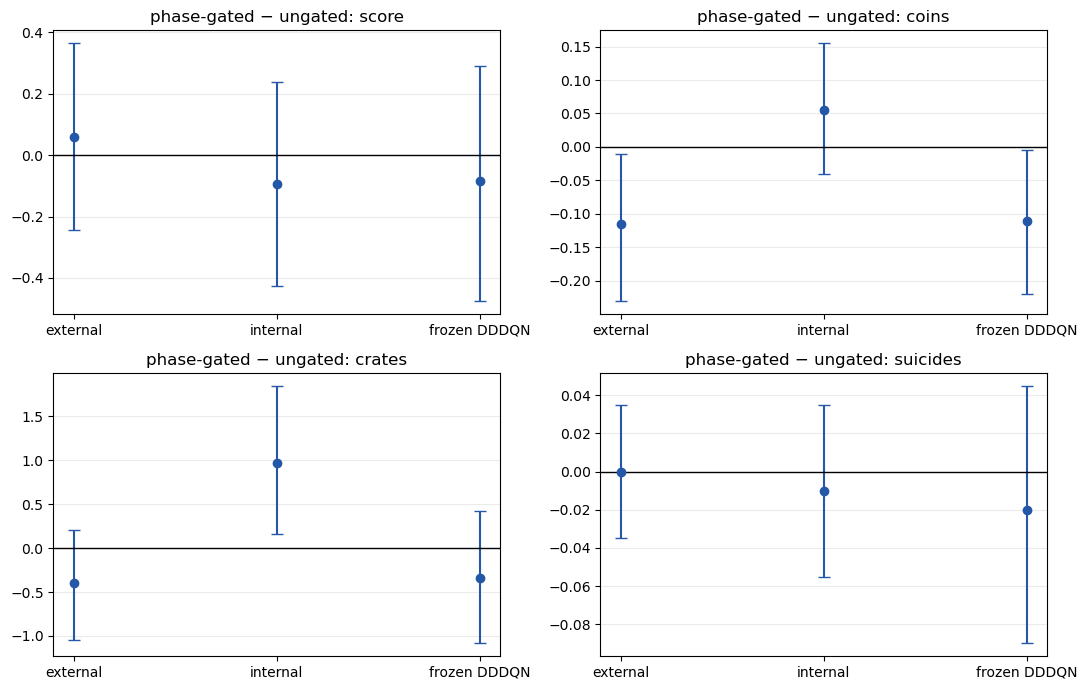

In [4]:
metrics = ['score', 'coins', 'crates', 'suicides']
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, metric in zip(axes.flat, metrics):
    part = primary[primary.metric == metric].set_index('lineup').loc[
        ['external_mixed','internal_mixed','frozen_dddqn']
    ]
    estimate = part.mean_difference.to_numpy()
    low = part.ci_low.to_numpy(); high = part.ci_high.to_numpy()
    ax.errorbar(np.arange(3), estimate,
                yerr=np.vstack([estimate-low, high-estimate]),
                fmt='o', capsize=4, color='#2457A7')
    ax.axhline(0, color='black', linewidth=1)
    ax.set_xticks(np.arange(3), ['external', 'internal', 'frozen DDDQN'])
    ax.set_title(f'phase-gated − ungated: {metric}')
    ax.grid(axis='y', alpha=.25)
fig.tight_layout()
figure_dir = RESULT_ROOT / 'figures'; figure_dir.mkdir(exist_ok=True)
fig.savefig(figure_dir / 'phase_minus_ungated_effects.png', dpi=180, bbox_inches='tight')
plt.show()

## Reference contrast and hunt-phase mechanism

Phase-gated and no-centre are identical during economic play by construction; their coin and crate outcomes are exactly equal in every lineup. The reference contrast asks whether the gated $.04$ term changes hunt behavior or downstream performance after economic objectives are exhausted.

In [5]:
reference = bootstrap[bootstrap.contrast == 'phase_gated-no_center'].copy()
reference[['ci_low', 'ci_high']] = pd.DataFrame(reference.ci95.tolist(), index=reference.index)
display(reference[
    reference.metric.isin(['score','hunt_center_distance','hunt_center_occupancy'])
][['lineup','metric','mean_difference','ci_low','ci_high']].round(4))

mechanism_columns = [
    'lineup','variant','hunt_center_distance',
    'hunt_center_progress_rate','hunt_center_occupancy','hunt_decisions',
]
display(aggregate[mechanism_columns].round(4))

,lineup,metric,mean_difference,ci_low,ci_high
10,external_mixed,score,0.0250,-0.0500,0.1000
17,external_mixed,hunt_center_distance,-0.0154,-0.0382,0.0061
19,external_mixed,hunt_center_occupancy,0.0071,-0.0045,0.0188
40,internal_mixed,score,0.0250,-0.1000,0.1500
47,internal_mixed,hunt_center_distance,-0.0267,-0.0417,-0.0121
49,internal_mixed,hunt_center_occupancy,0.0144,0.0058,0.0232
70,frozen_dddqn,score,0.0750,-0.0750,0.2500
77,frozen_dddqn,hunt_center_distance,-0.0232,-0.0420,-0.0061
79,frozen_dddqn,hunt_center_occupancy,0.0126,0.0035,0.0223


,lineup,variant,hunt_center_distance,hunt_center_progress_rate,hunt_center_occupancy,hunt_decisions
0,external_mixed,no_center,0.2468,0.0486,0.8572,135.200
1,external_mixed,phase_gated,0.2314,0.0476,0.8642,135.180
2,external_mixed,ungated_center,0.2110,0.0438,0.8731,133.935
3,internal_mixed,no_center,0.2948,0.0640,0.8200,175.335
4,internal_mixed,phase_gated,0.2681,0.0602,0.8344,174.935
5,internal_mixed,ungated_center,0.2680,0.0585,0.8363,177.485
6,frozen_dddqn,no_center,0.3384,0.0640,0.7983,157.535
7,frozen_dddqn,phase_gated,0.3152,0.0609,0.8109,158.930
8,frozen_dddqn,ungated_center,0.3183,0.0616,0.8089,151.150


## Results

- **Overall score:** there is no clear phase-gated versus ungated score difference in any pool. The paired effects are +0.060 in `external_mixed` (95% CI −0.245 to +0.365), −0.095 in `internal_mixed` (−0.425 to +0.240), and −0.085 in `frozen_dddqn` (−0.475 to +0.290).
- **Economic progress is opponent-pool dependent.** Ungated gains 0.115 coins/round over phase-gated in `external_mixed` (phase−ungated CI −0.230 to −0.010) and 0.110 in `frozen_dddqn` (−0.220 to −0.005). In contrast, phase-gated retains 0.975 more crates/round in `internal_mixed` (+0.160 to +1.850). Other crate/coin intervals include zero.
- **Safety is not consistently improved by gating.** Suicide and survival intervals include zero in all three pools. `internal_mixed` is the one clear protective case: phase-gated produces 0.410 fewer invalid actions/round than ungated (CI −0.685 to −0.150). Invalid-action intervals include zero in the other pools.
- **The gated heuristic changes hunt positioning without a demonstrated score gain.** Relative to no-centre, phase-gated reduces hunt centre distance and increases occupancy clearly in `internal_mixed` and `frozen_dddqn`; the external interval includes zero. Phase-gated versus no-centre score intervals include zero everywhere, while economic counts are exactly unchanged.

The pattern is mixed in exactly the way the locked rule treats as non-confirmatory: gating protects internal-mixed crate progress and legality, but the ungated preference improves coins in two other pools. No direction dominates overall score or safety across the opponent pools.

## Answer and design implication

**Answer: not generally.** The experiment does not support a cross-pool claim that phase-gating preserves economy and safety better than applying the same $.04$ centre preference throughout play. It supports a narrower architectural statement: gating prevents the heuristic from perturbing economic decisions and can be protective in at least one opponent pool, but that protection has an opportunity cost because ungated centring increased coin collection in two pools.

Accordingly, phase-gated centring may remain a conservative behavior-shaping choice, but it should not be presented as an established performance optimization. The centre component should stay secondary in the paper; stronger strategic claims should rest on components with direct and consistent practical effects, such as the safety mask and objective routing.

## Provenance and integrity checks

The following audit verifies all 1,800 represented rounds, one final protocol hash for the 200 newly materialized clusters, and identical five-round initial-condition hashes across the three variants for every lineup/seed pair. Quarantined pre-fix trials are outside the ledger and cannot enter this summary.

In [6]:
assert Counter(row['source'] for row in payload['ledger']) == {
    'phase_gating': 200, 'calibration': 160
}
protocol_hash = hashlib.sha256((RESULT_ROOT / 'protocol.json').read_bytes()).hexdigest()
local_protocol_hashes = set()
initial = defaultdict(dict)
for row in payload['ledger']:
    manifest = json.loads((ROOT / row['manifest']).read_text())
    initial[(row['lineup'], row['seed'])][row['variant']] = tuple(
        item['sha256'] for item in manifest['initial_conditions']
    )
    if row['source'] == 'phase_gating':
        local_protocol_hashes.add(manifest['protocol_sha256'])

audit = {
    'represented_rounds': len(payload['round_rows']),
    'seed_rows': len(payload['seed_rows']),
    'ledger_sources': dict(Counter(row['source'] for row in payload['ledger'])),
    'paired_lineup_seed_cells': len(initial),
    'all_initial_conditions_match': all(
        len(group) == 3 and len(set(group.values())) == 1 for group in initial.values()
    ),
    'one_final_protocol_for_new_runs': local_protocol_hashes == {protocol_hash},
    'protocol_sha256': protocol_hash,
    'implementation_sha256': protocol['implementation_sha256'],
}
assert audit['all_initial_conditions_match']
assert audit['one_final_protocol_for_new_runs']
audit

{'represented_rounds': 1800,
 'seed_rows': 360,
 'ledger_sources': {'calibration': 160, 'phase_gating': 200},
 'paired_lineup_seed_cells': 120,
 'all_initial_conditions_match': True,
 'one_final_protocol_for_new_runs': True,
 'protocol_sha256': '44ebe7dd94557a06972a11965f5b658328de76b0c11f37fae41390b22fd8106c',
 'implementation_sha256': '69e3c2e7e78df6d35834a47b1dfd732839a5c530e237d3cf7b0ef35ded64c8dd'}

## Reproduction entry points

The locked implementation is `evaluation/e1_phase_gating.py`; immutable inputs and criteria are recorded in `results/e1_phase_gating/protocol.json`; complete round-, seed-, aggregate-, bootstrap-, and ledger-level results are in `results/e1_phase_gating/summary.json`. The runner is resumable at one five-round seed cluster per manifest. It will refuse changed frozen inputs and will not overwrite valid runs.